**(a) P/E Ratio, P/B Ratio, Quarterly R&D Expense/Total Asset Ratios, Quarterly Firm Ages**

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime

stock = pd.read_excel("TRD_Mnth.xlsx", header = 1)
stock.head()

/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Stock Code,Trading Month,Monthly Opening Price,Monthly Closing Price,Market Value of Tradable Shares,Monthly Return With Cash Dividend Reinvested,Monthly Return Without Cash Dividend Reinvested
0,No Unit,No Unit,CNY/Share,CNY/Share,CNY 1000,No Unit,No Unit
1,000001,2000-01,17.5,18.53,19843822.88,0.061891,0.061891
2,000001,2000-02,19.2,18.32,19618933.36,-0.011333,-0.011333
3,000001,2000-03,18.4,18.37,19672478.48,0.002729,0.002729
4,000001,2000-04,18.38,19.05,20400692.17,0.037017,0.037017


In [ ]:
stock = stock[~stock['Stock Code'].astype(str).str.contains('No Unit|CNY|Unit', na=False)]
stock = stock[stock['Stock Code'].notna()]
stock = stock[stock['Stock Code'] != '']

print(f"After removing unit rows: {stock.shape}")
stock.head()

After removing unit rows: (760178, 7)


,Stock Code,Trading Month,Monthly Opening Price,Monthly Closing Price,Market Value of Tradable Shares,Monthly Return With Cash Dividend Reinvested,Monthly Return Without Cash Dividend Reinvested
1,000001,2000-01,17.5,18.53,19843822.88,0.061891,0.061891
2,000001,2000-02,19.2,18.32,19618933.36,-0.011333,-0.011333
3,000001,2000-03,18.4,18.37,19672478.48,0.002729,0.002729
4,000001,2000-04,18.38,19.05,20400692.17,0.037017,0.037017
5,000001,2000-05,19.12,18,19276244.57,-0.055118,-0.055118


In [ ]:
stock['trdmnt_date'] = pd.to_datetime(stock['Trading Month'], format='%Y-%m')
stock['year'] = stock['trdmnt_date'].dt.year
stock['quarter'] = stock['trdmnt_date'].dt.quarter
stock['year_quarter'] = stock['year'].astype(str) + 'Q' + stock['quarter'].astype(str)
stock['Stkcd'] = stock['Stock Code'].astype(str).str.zfill(6)

In [ ]:
clfrs = pd.read_excel("FS_Combas(Merge Query).xlsx", header=1)
clfrs.head()

/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Stock Code,Stock Short Name,Ending Date of Statistics,Statement Type,Total Assets,Total Liabilities,Establishment Date,Market Type,Earnings per Share 1,Net Assets per Share,Return on Assets - A,Return on Equity - A,R&D Expenses
0,No Unit,No Unit,No Unit,No Unit,CNY,CNY,NaN,NaN,No Unit,No Unit,No Unit,No Unit,CNY
1,000001,PAYH,2024-12-31,A,5769270000000,5274428000000,1987-12-22,4.0,2.293517,25.499433,0.007715,0.089944,NaN
2,000001,PAYH,2024-12-31,B,5726993000000,5239659000000,1987-12-22,4.0,2.194476,25.112543,0.007436,0.087386,NaN
3,000001,PAYH,2024-09-30,A,5745988000000,5255519000000,1987-12-22,4.0,2.047253,25.27409,0.006914,0.081002,NaN
4,000001,PAYH,2024-09-30,B,5712437000000,5229015000000,1987-12-22,4.0,1.970422,24.910955,0.006694,0.079099,NaN


In [ ]:
clfrs = clfrs[~clfrs['Stock Code'].astype(str).str.contains('No Unit|CNY|Unit', na=False)]
clfrs = clfrs[clfrs['Stock Code'].notna()]
clfrs = clfrs[clfrs['Stock Code'] != '']
print(f"After removing unit rows: {clfrs.shape}")
clfrs.head()

After removing unit rows: (608455, 17)


,Stock Code,Stock Short Name,Ending Date of Statistics,Statement Type,Total Assets,Total Liabilities,Establishment Date,Market Type,Earnings per Share 1,Net Assets per Share,Return on Assets - A,Return on Equity - A,R&D Expenses,Year,Quarter,Year_Quarter,Market Type Name
1,000001,PAYH,2024-12-31,A,5.769270e+12,5.274428e+12,1987-12-22,4.0,2.293517,25.499433,0.007715,0.089944,NaN,2024.0,4.0,2024.0Q4.0,GEM
2,000001,PAYH,2024-12-31,B,5.726993e+12,5.239659e+12,1987-12-22,4.0,2.194476,25.112543,0.007436,0.087386,NaN,2024.0,4.0,2024.0Q4.0,GEM
3,000001,PAYH,2024-09-30,A,5.745988e+12,5.255519e+12,1987-12-22,4.0,2.047253,25.274090,0.006914,0.081002,NaN,2024.0,3.0,2024.0Q3.0,GEM
4,000001,PAYH,2024-09-30,B,5.712437e+12,5.229015e+12,1987-12-22,4.0,1.970422,24.910955,0.006694,0.079099,NaN,2024.0,3.0,2024.0Q3.0,GEM
5,000001,PAYH,2024-06-30,A,5.754033e+12,5.272164e+12,1987-12-22,4.0,1.333557,24.830929,0.004498,0.053705,NaN,2024.0,2.0,2024.0Q2.0,GEM


In [ ]:
clfrs['Stock Code'] = clfrs['Stock Code'].astype(str).str.zfill(6)
numeric_cols = ['Total Assets', 'Total Liabilities', 'Earnings per Share 1',
                'Net Assets per Share', 'Return on Assets - A', 'Return on Equity - A',
                'R&D Expenses']

print("\nConverting numeric columns:")
for col in numeric_cols:
    if col in clfrs.columns:
        clfrs[col] = pd.to_numeric(clfrs[col], errors='coerce') #convert to numeric values and force errors = nan
        non_null = clfrs[col].notna().sum()
        print(f"  {col}: {non_null:>8,} non-null values")

for col in ['Earnings per Share 1', 'Net Assets per Share']:
    if col in clfrs.columns:
        zero_count = (clfrs[col] == 0).sum()
        print(f"  {col}: {zero_count:,} zero values ({zero_count/len(clfrs)*100:.2f}%)")


Converting numeric columns:
  Total Assets:  608,448 non-null values
  Total Liabilities:  608,406 non-null values
  Earnings per Share 1:  474,755 non-null values
  Net Assets per Share:  474,693 non-null values
  Return on Assets - A:  474,861 non-null values
  Return on Equity - A:  469,079 non-null values
  R&D Expenses:  228,361 non-null values
  Earnings per Share 1: 20 zero values (0.00%)
  Net Assets per Share: 15 zero values (0.00%)


In [ ]:
clfrs['Ending Date of Statistics'] = pd.to_datetime(clfrs['Ending Date of Statistics'], errors='coerce')
clfrs['Establishment Date'] = pd.to_datetime(clfrs['Establishment Date'], errors='coerce')
clfrs = clfrs.dropna(subset=['Ending Date of Statistics'])
print(f"\nAfter removing invalid dates: {len(clfrs)} rows")


After removing invalid dates: 608455 rows


In [ ]:
clfrs['year'] = clfrs['Ending Date of Statistics'].dt.year
clfrs['quarter'] = clfrs['Ending Date of Statistics'].dt.quarter
clfrs['year_quarter'] = clfrs['year'].astype(str) + 'Q' + clfrs['quarter'].astype(str)
print(f"\nFinancial data date range: {clfrs['Ending Date of Statistics'].min()} to {clfrs['Ending Date of Statistics'].max()}")


Financial data date range: 2000-01-01 00:00:00 to 2024-12-31 00:00:00


In [ ]:
market_type_map = {
    1: 'Main Board (Shanghai)',
    2: 'Main Board (Shenzhen)',
    4: 'GEM',
    8: 'SME Board'
}

clfrs['Market Type Name'] = clfrs['Market Type'].map(market_type_map)
print(clfrs['Market Type Name'].value_counts(dropna=False))

Market Type Name
Main Board (Shanghai)    245517
GEM                      231439
NaN                      131499
Name: count, dtype: int64


In [ ]:
print(clfrs['Statement Type'].value_counts())

# only consider consolidated statements (type A)
quarterly_data = clfrs[clfrs['Statement Type'] == 'A'].copy()
print(f"\nRows with Type A (consolidated): {len(quarterly_data)}")

Statement Type
A    330794
B    277661
Name: count, dtype: int64

Rows with Type A (consolidated): 330794


In [ ]:
dupes = quarterly.duplicated(subset=['Stock Code', 'year_quarter'], keep=False) #remove duplicates
if dupes.any():
    print(f"Found {dupes.sum()} duplicate entries")
    quarterly = quarterly.drop_duplicates(subset=['Stock Code', 'year_quarter'], keep='first')
    print(f"After removing duplicates: {len(quarterly)} rows")

Found 122990 duplicate entries
After removing duplicates: 269299 rows


In [ ]:
merged = pd.merge( #merge the two files
    stock,
    quarterly[['Stock Code', 'year_quarter',
               'Total Assets', 'Total Liabilities',
               'Earnings per Share 1', 'Net Assets per Share',
               'Return on Assets - A', 'Return on Equity - A',
               'R&D Expenses', 'Establishment Date', 'Market Type Name']],
    left_on=['Stkcd', 'year_quarter'],
    right_on=['Stock Code', 'year_quarter'],
    how='left'
)
print(f"Merged data shape: {merged.shape}")
print(f"Match rate: {merged['Earnings per Share 1'].notna().mean()*100:.1f}%")

Merged data shape: (760178, 22)
Match rate: 98.1%


In [ ]:
#calculate P/E
mask_pe = (merged['Earnings per Share 1'].notna()) & (merged['Earnings per Share 1'] != 0)
merged['PE_Ratio'] = np.nan
merged.loc[mask_pe, 'PE_Ratio'] = merged.loc[mask_pe, 'Monthly Closing Price'] / merged.loc[mask_pe, 'Earnings per Share 1']
print(f"Valid EPS values: {mask_pe.sum():,}")
print(f"P/E Ratio: {merged['PE_Ratio'].notna().sum():,} valid observations")
pe_samples = merged[merged['PE_Ratio'].notna()][['Stkcd', 'Trading Month', 'Monthly Closing Price', 'Earnings per Share 1', 'PE_Ratio']].head(10)
print(pe_samples.to_string())

/tmp/ipykernel_606/3845239843.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[166.12599413980746 156.96944328170784 158.10311148318684 ...
 77.81456068198713 96.69328227699843 73.21521207810335]' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  merged.loc[mask_pe, 'PE_Ratio'] = merged.loc[mask_pe, 'Monthly Closing Price'] / merged.loc[mask_pe, 'Earnings per Share 1']


Valid EPS values: 745,948
P/E Ratio: 745,948 valid observations
     Stkcd Trading Month Monthly Closing Price  Earnings per Share 1    PE_Ratio
3   000001       2000-04                 19.05              0.114672  166.125994
4   000001       2000-05                    18              0.114672  156.969443
5   000001       2000-06                 18.13              0.114672  158.103111
9   000001       2000-10                 17.55              0.260328   67.414953
10  000001       2000-11                 15.49              0.260328   59.501859
11  000001       2000-12                 14.52              0.260328   55.775791
15  000001       2001-04                 15.53              0.114713  135.381343
16  000001       2001-05                  16.2              0.114713  141.222006
17  000001       2001-06                 15.31              0.114713  133.463513
21  000001       2001-10                 13.81              0.206782    66.78531


In [ ]:
#calculate P/B
mask_pb = (merged['Net Assets per Share'].notna()) & (merged['Net Assets per Share'] != 0)
merged['PB_Ratio'] = np.nan
merged.loc[mask_pb, 'PB_Ratio'] = merged.loc[mask_pb, 'Monthly Closing Price'] / merged.loc[mask_pb, 'Net Assets per Share']
print(f"Valid Net Assets values: {mask_pb.sum():,}")
print(f"P/B Ratio: {merged['PB_Ratio'].notna().sum():,} valid observations")
pb_samples = merged[merged['PB_Ratio'].notna()][['Stkcd', 'Trading Month', 'Monthly Closing Price', 'Net Assets per Share', 'PB_Ratio']].head(10)
print(pb_samples.to_string())

/tmp/ipykernel_606/1551074022.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[9.602913236544707 9.073618806183974 9.13915049756197 ...
 2.3007037149012235 2.858881317210592 2.1647171035737283]' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  merged.loc[mask_pb, 'PB_Ratio'] = merged.loc[mask_pb, 'Monthly Closing Price'] / merged.loc[mask_pb, 'Net Assets per Share']


Valid Net Assets values: 745,741
P/B Ratio: 745,741 valid observations
     Stkcd Trading Month Monthly Closing Price  Net Assets per Share  PB_Ratio
3   000001       2000-04                 19.05              1.983773  9.602913
4   000001       2000-05                    18              1.983773  9.073619
5   000001       2000-06                 18.13              1.983773   9.13915
9   000001       2000-10                 17.55              2.435415  7.206164
10  000001       2000-11                 15.49              2.435415  6.360312
11  000001       2000-12                 14.52              2.435415  5.962023
15  000001       2001-04                 15.53              2.549989  6.090222
16  000001       2001-05                  16.2              2.549989  6.352969
17  000001       2001-06                 15.31              2.549989  6.003947
21  000001       2001-10                 13.81              1.864337  7.407459


In [ ]:
#calculate R&D to Assets Ratio
mask_rd = (merged['Total Assets'].notna()) & (merged['Total Assets'] != 0) & (merged['R&D Expenses'].notna())
merged['RD_to_Assets'] = np.nan
merged.loc[mask_rd, 'RD_to_Assets'] = merged.loc[mask_rd, 'R&D Expenses'] / merged.loc[mask_rd, 'Total Assets']
print(f"Valid Total Assets values: {(merged['Total Assets'].notna() & (merged['Total Assets'] != 0)).sum():,}")
print(f"R&D/Assets: {merged['RD_to_Assets'].notna().sum():,} valid observations")
rd_samples = merged[merged['RD_to_Assets'].notna()][['Stkcd', 'Trading Month', 'R&D Expenses', 'Total Assets', 'RD_to_Assets']].head(10)
print(rd_samples.to_string(index=False))

Valid Total Assets values: 752,696
R&D/Assets: 314,059 valid observations
 Stkcd Trading Month  R&D Expenses  Total Assets  RD_to_Assets
000002       2018-07  375153269.41  1.432222e+12      0.000262
000002       2018-08  375153269.41  1.432222e+12      0.000262
000002       2018-09  375153269.41  1.432222e+12      0.000262
000002       2018-10  946064361.26  1.528579e+12      0.000619
000002       2018-11  946064361.26  1.528579e+12      0.000619
000002       2018-12  946064361.26  1.528579e+12      0.000619
000002       2019-01  118992200.16  1.551166e+12      0.000077
000002       2019-02  118992200.16  1.551166e+12      0.000077
000002       2019-03  118992200.16  1.551166e+12      0.000077
000002       2019-04  429777726.92  1.577057e+12      0.000273


In [ ]:
#calculate firm age
mask_age = merged['Establishment Date'].notna()
merged['Firm_Age_Days'] = np.nan
merged.loc[mask_age, 'Firm_Age_Days'] = (merged.loc[mask_age, 'trdmnt_date'] - merged.loc[mask_age, 'Establishment Date']).dt.days
merged['Firm_Age_Years'] = merged['Firm_Age_Days'] / 365.25
print(f"  Valid Establishment Date: {mask_age.sum():,}")
print(f"  ✓ Firm Age: {merged['Firm_Age_Years'].notna().sum():,} valid observations")
age_samples = merged[merged['Firm_Age_Years'].notna()][['Stkcd', 'Trading Month', 'Establishment Date', 'Firm_Age_Years']].head(10)
print(age_samples.to_string(index=False))

  Valid Establishment Date: 752,807
  ✓ Firm Age: 752,807 valid observations
 Stkcd Trading Month Establishment Date  Firm_Age_Years
000001       2000-01         1987-12-22       12.027379
000001       2000-02         1987-12-22       12.112252
000001       2000-03         1987-12-22       12.191650
000001       2000-04         1987-12-22       12.276523
000001       2000-05         1987-12-22       12.358658
000001       2000-06         1987-12-22       12.443532
000001       2000-10         1987-12-22       12.777550
000001       2000-11         1987-12-22       12.862423
000001       2000-12         1987-12-22       12.944559
000001       2001-01         1987-12-22       13.029432


**(b) Summary Statistics (monthly stock returns, P/E ratios, P/B ratios and quarterly ROA, ROE, R&D expense / total asset ratios, firm ages); Main Board vs. GEM Board**

In [ ]:
#general statistics
def print_stats(data, name):
    if data.notna().sum() > 0:
        print(f"\n{name}:")
        print(f"  Observations: {data.notna().sum():,}")
        print(f"  Mean: {data.mean():.2f}")
        print(f"  Median: {data.median():.2f}")
        print(f"  Std Dev: {data.std():.2f}")
        print(f"  Min: {data.min():.2f}")
        print(f"  Max: {data.max():.2f}")
        print(f"  p25: {data.quantile(0.25):.2f}")
        print(f"  p75: {data.quantile(0.75):.2f}")

print_stats(merged['PE_Ratio'], "P/E Ratio")
print_stats(merged['PB_Ratio'], "P/B Ratio")
print_stats(merged['RD_to_Assets'], "R&D/Assets Ratio")
print_stats(merged['Firm_Age_Years'], "Firm Age (years)")


P/E Ratio:
  Observations: 745,948
  Mean: 149.62
  Median: 50.86
  Std Dev: 8597.54
  Min: -3525000.00
  Max: 928750.00
  p25: 19.20
  p75: 125.81

P/B Ratio:
  Observations: 745,741
  Mean: 2.63
  Median: 2.64
  Std Dev: 558.00
  Min: -305000.00
  Max: 20453.02
  p25: 1.67
  p75: 4.27

R&D/Assets Ratio:
  Observations: 314,059
  Mean: 0.02
  Median: 0.01
  Std Dev: 0.02
  Min: -0.00
  Max: 0.70
  p25: 0.00
  p75: 0.02

Firm Age (years):
  Observations: 752,807
  Mean: 17.86
  Median: 17.61
  Std Dev: 7.29
  Min: 0.00
  Max: 73.92
  p25: 12.61
  p75: 22.63


In [ ]:
def print_detailed_stats(data, group_name):
    print(f"\n{group_name}")

    stats_list = []

    for var, var_name in [
        ('PE_Ratio', 'P/E Ratio'),
        ('PB_Ratio', 'P/B Ratio'),
        ('RD_to_Assets', 'R&D/Assets'),
        ('Firm_Age_Years', 'Firm Age (years)'),
        ('Return on Assets - A', 'ROA'),
        ('Return on Equity - A', 'ROE'),
        ('Monthly Return With Cash Dividend Reinvested', 'Monthly Returns')
    ]:
        if var in data.columns:
            values = data[var].dropna()
            if len(values) > 0:
                if var in ['PE_Ratio', 'PB_Ratio']:
                    lower = values.quantile(0.01)
                    upper = values.quantile(0.99)
                    values_clean = values[(values >= lower) & (values <= upper)]
                else:
                    values_clean = values

                print(f"\n{var_name}:")
                print(f"  Observations: {len(values_clean):,}")
                print(f"  Mean: {values_clean.mean():.4f}")
                print(f"  Median: {values_clean.median():.4f}")
                print(f"  Std Dev: {values_clean.std():.4f}")
                print(f"  Min: {values_clean.min():.4f}")
                print(f"  Max: {values_clean.max():.4f}")
                print(f"  p25: {values_clean.quantile(0.25):.4f}")
                print(f"  p75: {values_clean.quantile(0.75):.4f}")

In [ ]:
main_board_types = ['Main Board (Shanghai)', 'Main Board (Shenzhen)']
gem_type = ['GEM']

In [ ]:
#stats for main board
main_board_data = merged[merged['Market Type Name'].isin(main_board_types)]
gem_data = merged[merged['Market Type Name'].isin(gem_type)]
print(f"\nMAIN BOARD (Shanghai + Shenzhen)")
print(f"Observations: {len(main_board_data):,}")
print_detailed_stats(main_board_data, "MAIN BOARD")


MAIN BOARD (Shanghai + Shenzhen)
Observations: 311,396

MAIN BOARD

P/E Ratio:
  Observations: 301,938
  Mean: 101.7003
  Median: 44.5128
  Std Dev: 272.8711
  Min: -913.6213
  Max: 2660.4182
  p25: 17.6758
  p75: 108.4740

P/B Ratio:
  Observations: 301,922
  Mean: 3.2081
  Median: 2.3499
  Std Dev: 2.9147
  Min: -1.1963
  Max: 26.6264
  p25: 1.4863
  p75: 3.8559

R&D/Assets:
  Observations: 102,799
  Mean: 0.0122
  Median: 0.0076
  Std Dev: 0.0159
  Min: -0.0023
  Max: 0.2723
  p25: 0.0022
  p75: 0.0168

Firm Age (years):
  Observations: 311,396
  Mean: 17.7076
  Median: 17.6044
  Std Dev: 7.4312
  Min: 0.0000
  Max: 66.9158
  p25: 12.1314
  p75: 23.0452

ROA:
  Observations: 308,126
  Mean: 0.0177
  Median: 0.0158
  Std Dev: 0.2353
  Min: -48.3159
  Max: 7.6960
  p25: 0.0042
  p75: 0.0371

ROE:
  Observations: 304,432
  Mean: 0.0104
  Median: 0.0354
  Std Dev: 1.5428
  Min: -274.0481
  Max: 281.9892
  p25: 0.0106
  p75: 0.0744

Monthly Returns:
  Observations: 310,096
  Mean: 0.011

In [ ]:
#stats for GEM board
print(f"GEM BOARD")
print(f"Observations: {len(gem_data):,}")
print_detailed_stats(gem_data, "GEM BOARD")

GEM BOARD
Observations: 289,663

GEM BOARD

P/E Ratio:
  Observations: 280,378
  Mean: 110.5103
  Median: 49.7175
  Std Dev: 307.5630
  Min: -1074.3194
  Max: 2845.7927
  p25: 19.1308
  p75: 122.8411

P/B Ratio:
  Observations: 280,189
  Mean: 3.4108
  Median: 2.6243
  Std Dev: 2.7785
  Min: -0.6754
  Max: 22.7390
  p25: 1.6717
  p75: 4.1598

R&D/Assets:
  Observations: 99,856
  Mean: 0.0134
  Median: 0.0086
  Std Dev: 0.0157
  Min: -0.0002
  Max: 0.7016
  p25: 0.0031
  p75: 0.0187

Firm Age (years):
  Observations: 289,663
  Mean: 18.2424
  Median: 17.9028
  Std Dev: 7.8707
  Min: 0.1862
  Max: 73.9247
  p25: 12.5613
  p75: 23.1896

ROA:
  Observations: 286,374
  Mean: 0.0857
  Median: 0.0157
  Std Dev: 44.3070
  Min: -2146.1613
  Max: 23509.7686
  p25: 0.0034
  p75: 0.0377

ROE:
  Observations: 282,938
  Mean: 0.0244
  Median: 0.0309
  Std Dev: 3.1600
  Min: -186.5570
  Max: 713.2036
  p25: 0.0079
  p75: 0.0688

Monthly Returns:
  Observations: 288,517
  Mean: 0.0131
  Median: 0.0000

In [ ]:
#comparison table
comparison_data = []

for var, var_name in [
    ('PE_Ratio', 'P/E Ratio'),
    ('PB_Ratio', 'P/B Ratio'),
    ('RD_to_Assets', 'R&D/Assets'),
    ('Firm_Age_Years', 'Firm Age'),
    ('Return on Assets - A', 'ROA'),
    ('Return on Equity - A', 'ROE'),
    ('Monthly Return With Cash Dividend Reinvested', 'Monthly Returns')
]:
    if var in merged.columns:
        mb_values = main_board_data[var].dropna()
        gem_values = gem_data[var].dropna()

        if len(mb_values) > 0 and len(gem_values) > 0: #handle outliers
            if var in ['PE_Ratio', 'PB_Ratio']:
                mb_clean = mb_values[(mb_values >= mb_values.quantile(0.01)) & (mb_values <= mb_values.quantile(0.99))]
                gem_clean = gem_values[(gem_values >= gem_values.quantile(0.01)) & (gem_values <= gem_values.quantile(0.99))]
            else:
                mb_clean = mb_values
                gem_clean = gem_values

            comparison_data.append({
                'Variable': var_name,
                'Main Board N': len(mb_clean),
                'Main Board Mean': mb_clean.mean(),
                'Main Board Median': mb_clean.median(),
                'Main Board Std': mb_clean.std(),
                'Main Board p25': mb_clean.quantile(0.25),
                'Main Board p75': mb_clean.quantile(0.75),
                'GEM N': len(gem_clean),
                'GEM Mean': gem_clean.mean(),
                'GEM Median': gem_clean.median(),
                'GEM Std': gem_clean.std(),
                'GEM p25': gem_clean.quantile(0.25),
                'GEM p75': gem_clean.quantile(0.75),
                'Difference (Mean)': mb_clean.mean() - gem_clean.mean(),
                'Difference (%)': ((mb_clean.mean() - gem_clean.mean()) / gem_clean.mean()) * 100
            })

comparison_df = pd.DataFrame(comparison_data)
print("MAIN BOARD vs GEM - COMPARISON TABLE")
print(comparison_df.to_string(index=False, float_format="%.4f"))

MAIN BOARD vs GEM - COMPARISON TABLE
       Variable  Main Board N  Main Board Mean  Main Board Median  Main Board Std  Main Board p25  Main Board p75  GEM N  GEM Mean  GEM Median  GEM Std  GEM p25  GEM p75  Difference (Mean)  Difference (%)
      P/E Ratio        301938         101.7003            44.5128        272.8711         17.6758        108.4740 280378  110.5103     49.7175 307.5630  19.1308 122.8411            -8.8101         -7.9722
      P/B Ratio        301922           3.2081             2.3499          2.9147          1.4863          3.8559 280189    3.4108      2.6243   2.7785   1.6717   4.1598            -0.2027         -5.9431
     R&D/Assets        102799           0.0122             0.0076          0.0159          0.0022          0.0168  99856    0.0134      0.0086   0.0157   0.0031   0.0187            -0.0012         -9.1034
       Firm Age        311396          17.7076            17.6044          7.4312         12.1314         23.0452 289663   18.2424     17.9028 

Please refer to the pdf for comparison on summary statistics.

**2. Plotting Two Time-Series for Median P/E Ratio by Market
Type**

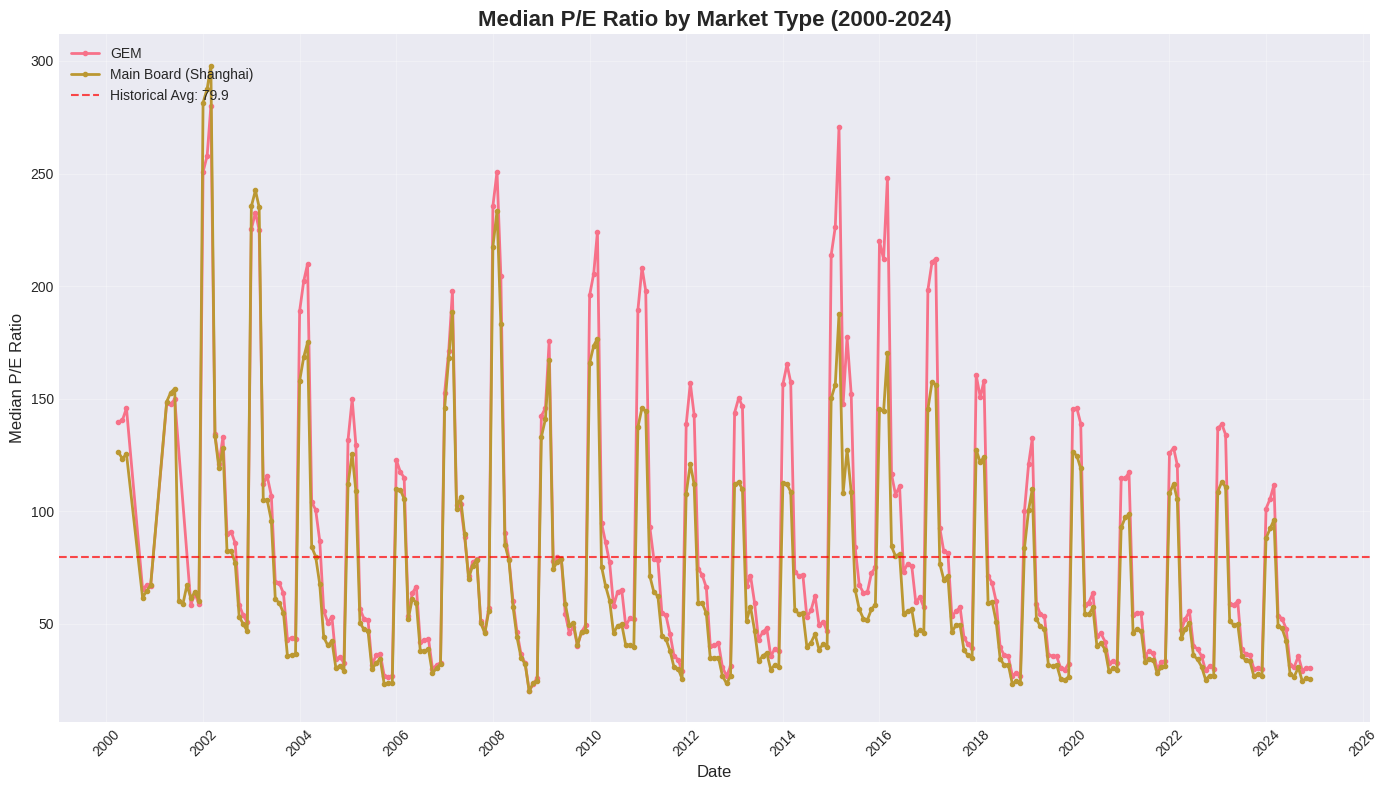

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

pe_data = merged[['Stkcd', 'trdmnt_date', 'Market Type Name', 'PE_Ratio']].copy()
pe_data = pe_data.dropna(subset=['PE_Ratio', 'Market Type Name'])
pe_data = pe_data[pe_data['PE_Ratio'] > 0]

for market in pe_data['Market Type Name'].unique():
    market_data = pe_data[pe_data['Market Type Name'] == market]['PE_Ratio']
    lower = market_data.quantile(0.01)
    upper = market_data.quantile(0.99)
    pe_data = pe_data[~((pe_data['Market Type Name'] == market) &
                        ((pe_data['PE_Ratio'] < lower) | (pe_data['PE_Ratio'] > upper)))]

pe_time_series = pe_data.groupby(['trdmnt_date', 'Market Type Name'])['PE_Ratio'].median().reset_index()
pe_time_series = pe_time_series.rename(columns={'PE_Ratio': 'Median_PE'})

#plot
fig, ax = plt.subplots(figsize=(14, 8))
for market in pe_time_series['Market Type Name'].unique():
    if market in ['Main Board (Shanghai)', 'Main Board (Shenzhen)', 'GEM']:
        market_data = pe_time_series[pe_time_series['Market Type Name'] == market]
        ax.plot(market_data['trdmnt_date'], market_data['Median_PE'],
                label=market, linewidth=2, marker='o', markersize=3)
historical_avg = pe_time_series['Median_PE'].mean()
ax.axhline(y=historical_avg, color='red', linestyle='--', alpha=0.7,
           label=f'Historical Avg: {historical_avg:.1f}')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Median P/E Ratio', fontsize=12)
ax.set_title('Median P/E Ratio by Market Type (2000-2024)', fontsize=16, fontweight='bold')
ax.legend(fontsize=10, loc='upper left')
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator(2))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('pe_ratio_time_series.png', dpi=300, bbox_inches='tight')
plt.show()

**Please refer to the pdf for analysis.**